In [1]:
!pip install -q iterative-stratification

In [4]:
import random
import time
from pathlib import Path

import albumentations as A
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import timm
import torch
import torch.nn as nn
from sklearn.metrics import average_precision_score, f1_score
from torch.utils.data import DataLoader, Dataset
from pathlib import Path

import numpy as np
import pandas as pd
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

In [9]:
IS_KAGGLE = Path("/kaggle/input").exists()
DATA_DIR = Path("/kaggle/input/competitions/cats-and-dogs") if IS_KAGGLE else Path("Data")
OUT_CSV = Path("/kaggle/working/train_folds.csv") if IS_KAGGLE else Path("Data/folds/train_folds.csv")

SEED, K = 6769, 5
LABELS = ["Cat", "Dog", "Moris", "Motya", "Biatrix"]

train_y = pd.read_csv(DATA_DIR / "train.csv")

fold = np.full(len(train_y), -1)
mskf = MultilabelStratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
for f, (_, val_idx) in enumerate(mskf.split(train_y, train_y[LABELS])):
    fold[val_idx] = f
train_y["fold"] = fold

assert (train_y["fold"] >= 0).all()
OUT_CSV.parent.mkdir(parents=True, exist_ok=True)
train_y.to_csv(OUT_CSV, index=False)

print(train_y["fold"].value_counts().sort_index())
print(train_y.groupby("fold")[LABELS].sum())

fold
0    2452
1    2452
2    2452
3    2452
4    2452
Name: count, dtype: int64
       Cat   Dog  Moris  Motya  Biatrix
fold                                   
0     1015  1005     11      8        9
1     1016  1005     11      9        8
2     1015  1005     11      8        8
3     1016  1005     11      8        8
4     1015  1005     12      9        8


In [18]:
def set_seed(seed=6769):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"

DATA_DIR = Path("/kaggle/input/competitions/cats-and-dogs")
FOLDS_CSV = Path("/kaggle/working/train_folds.csv")
LABELS = ["Cat", "Dog", "Moris", "Motya", "Biatrix"]

MODEL_NAME = "efficientnet_b3.ra2_in1k"
H, W = 384, 448
BATCH_SIZE = 32
EPOCHS = 5
LR, WD = 3e-4, 1e-2
REPEAT = 5
FOLDS_TO_RUN = range(5)            
NUM_WORKERS = 4

In [19]:
train_tf = A.Compose([
    A.Resize(H, W),
    A.HorizontalFlip(p=0.5),
    A.Affine(scale=(0.9, 1.1), rotate=(-15, 15), p=0.5),
    A.RandomBrightnessContrast(0.15, 0.15, p=0.5),
])
test_tf = A.Compose([A.Resize(H, W)])

mean = torch.tensor((0.485, 0.456, 0.406), device=device).view(1, 3, 1, 1)
std = torch.tensor((0.229, 0.224, 0.225), device=device).view(1, 3, 1, 1)


def prep(x):
    """uint8 batch -> GPU, 0-1, ImageNet normalisation."""
    return ((x.to(device).float() / 255) - mean) / std

In [20]:
class JpgDataset(Dataset):

    def __init__(self, ids, img_dir, labels, transform):
        self.ids, self.img_dir, self.labels, self.transform = ids, Path(img_dir), labels, transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        img = cv2.cvtColor(cv2.imread(str(self.img_dir / f"{self.ids[i]}.jpg")), cv2.COLOR_BGR2RGB)
        img = self.transform(image=img)["image"]
        return torch.from_numpy(img).permute(2, 0, 1), torch.from_numpy(self.labels[i])


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", zero_division=0)


def best_thresholds(y_true, y_prob, grid=np.arange(0.02, 0.98, 0.01)):
    """One threshold per class, chosen to maximise that class's F1."""
    th = []
    for j in range(y_true.shape[1]):
        scores = [f1_score(y_true[:, j], y_prob[:, j] >= t, zero_division=0) for t in grid]
        th.append(grid[int(np.argmax(scores))])
    return np.array(th)


def evaluate_oof(y_true, oof_prob, fold):
    fixed = macro_f1(y_true, oof_prob >= 0.5)
    tuned = macro_f1(y_true, oof_prob >= best_thresholds(y_true, oof_prob))   # optimistic

    pred = np.zeros_like(y_true)
    for f in np.unique(fold):
        va = fold == f
        th = best_thresholds(y_true[~va], oof_prob[~va])
        pred[va] = oof_prob[va] >= th
    honest = macro_f1(y_true, pred)
    return {"fixed_0.5": fixed, "tuned_on_oof": tuned, "tuned_honest": honest}


df = pd.read_csv(FOLDS_CSV)
ids, folds = df["image_id"].values, df["fold"].values
Y = df[LABELS].values.astype(np.float32)

In [23]:
oof = np.zeros((len(df), len(LABELS)), dtype=np.float32)
history = []
for fold in FOLDS_TO_RUN:
    tr, va = np.where(folds != fold)[0], np.where(folds == fold)[0]
    rare = tr[Y[tr, 2:].any(axis=1)]
    tr = np.concatenate([tr, np.repeat(rare, REPEAT - 1)])

    train_loader = DataLoader(JpgDataset(ids[tr], DATA_DIR / "train", Y[tr], train_tf),
                              batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                              num_workers=NUM_WORKERS, pin_memory=use_amp)
    val_loader = DataLoader(JpgDataset(ids[va], DATA_DIR / "train", Y[va], test_tf),
                            batch_size=BATCH_SIZE * 2, shuffle=False,
                            num_workers=NUM_WORKERS, pin_memory=use_amp)

    pos = Y[tr].sum(0)
    pos_weight = torch.tensor(np.sqrt((len(tr) - pos) / pos), dtype=torch.float32, device=device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    model = timm.create_model(MODEL_NAME, pretrained=True, num_classes=len(LABELS), drop_rate=0.2).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS * len(train_loader))
    scaler = torch.amp.GradScaler(enabled=use_amp)
    y_va = torch.from_numpy(Y[va]).to(device)

    best_ap = -1.0
    for epoch in range(EPOCHS):
        model.train()
        t0, total = time.time(), 0.0
        for x, y in train_loader:
            x, y = prep(x), y.to(device)
            optimizer.zero_grad()
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                out = model(x)
            loss = criterion(out.float(), y)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            total += loss.item()

        model.eval()
        with torch.no_grad():
            val_logs = torch.cat([model(prep(x)) for x, _ in val_loader]).float()
        val_loss = criterion(val_logs, y_va).item()
        p = torch.sigmoid(val_logs).cpu().numpy()
        ap = average_precision_score(Y[va].astype(int), p, average=None)
        f1s = f1_score(Y[va].astype(int), p >= 0.5, average=None, zero_division=0)
        history.append({"fold": fold, "epoch": epoch, "train_loss": total / len(train_loader),
                        "val_loss": val_loss, "val_ap": ap.mean(), "val_f1": f1s.mean()})
        print(f"fold {fold} epoch {epoch:2d}  train {total / len(train_loader):.4f}  val {val_loss:.4f}  "
              f"macroAP {ap.mean():.4f}  macroF1@0.5 {f1s.mean():.4f}  per-class {np.round(f1s, 2)}  "
              f"{time.time() - t0:.0f}s")

        if ap.mean() > best_ap:
            best_ap, best_epoch, best_p = ap.mean(), epoch, p
            torch.save(model.state_dict(), f"effb3_baseline_fold{fold}.pt")

    oof[va] = best_p
    print(f"fold {fold}: best epoch {best_epoch}, macro AP {best_ap:.4f}")

/tmp/ipykernel_49/3740347158.py:40: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


fold 0 epoch  0  train 0.0711  val 0.0262  macroAP 0.9464  macroF1@0.5 0.9101  per-class [0.99 0.99 0.9  0.67 1.  ]  179s
fold 0 epoch  1  train 0.0080  val 0.0131  macroAP 0.9828  macroF1@0.5 0.9427  per-class [1.   0.99 0.9  0.88 0.95]  178s
fold 0 epoch  2  train 0.0035  val 0.0129  macroAP 0.9812  macroF1@0.5 0.9390  per-class [1.   0.99 0.96 0.75 1.  ]  178s
fold 0 epoch  3  train 0.0011  val 0.0099  macroAP 0.9831  macroF1@0.5 0.9481  per-class [1.   0.99 1.   0.75 1.  ]  177s
fold 0 epoch  4  train 0.0010  val 0.0103  macroAP 0.9831  macroF1@0.5 0.9281  per-class [1.   0.99 1.   0.75 0.9 ]  177s
fold 0: best epoch 3, macro AP 0.9831


/tmp/ipykernel_49/3740347158.py:40: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


fold 1 epoch  0  train 0.0683  val 0.0149  macroAP 0.9750  macroF1@0.5 0.9222  per-class [0.99 0.99 0.91 0.78 0.94]  179s
fold 1 epoch  1  train 0.0082  val 0.0103  macroAP 0.9960  macroF1@0.5 0.9267  per-class [0.99 0.99 0.83 0.88 0.94]  179s
fold 1 epoch  2  train 0.0037  val 0.0094  macroAP 0.9971  macroF1@0.5 0.9651  per-class [0.99 0.99 0.95 0.95 0.94]  178s
fold 1 epoch  3  train 0.0011  val 0.0085  macroAP 0.9972  macroF1@0.5 0.9657  per-class [0.99 0.99 0.95 0.95 0.94]  178s
fold 1 epoch  4  train 0.0007  val 0.0072  macroAP 0.9972  macroF1@0.5 0.9765  per-class [1.   0.99 0.95 1.   0.94]  178s
fold 1: best epoch 4, macro AP 0.9972


/tmp/ipykernel_49/3740347158.py:40: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


fold 2 epoch  0  train 0.0638  val 0.0111  macroAP 0.9971  macroF1@0.5 0.9652  per-class [0.99 0.99 1.   1.   0.84]  179s
fold 2 epoch  1  train 0.0116  val 0.0123  macroAP 0.9999  macroF1@0.5 0.9845  per-class [0.99 0.99 1.   0.94 1.  ]  179s
fold 2 epoch  2  train 0.0032  val 0.0080  macroAP 0.9999  macroF1@0.5 0.9884  per-class [0.99 0.99 0.96 1.   1.  ]  178s
fold 2 epoch  3  train 0.0010  val 0.0059  macroAP 0.9999  macroF1@0.5 0.9865  per-class [1.   0.99 1.   0.94 1.  ]  178s
fold 2 epoch  4  train 0.0010  val 0.0058  macroAP 0.9999  macroF1@0.5 0.9865  per-class [1.   1.   1.   0.94 1.  ]  178s
fold 2: best epoch 4, macro AP 0.9999


/tmp/ipykernel_49/3740347158.py:40: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


fold 3 epoch  0  train 0.0674  val 0.0105  macroAP 0.9967  macroF1@0.5 0.9485  per-class [0.99 0.99 0.92 1.   0.84]  179s
fold 3 epoch  1  train 0.0081  val 0.0070  macroAP 0.9999  macroF1@0.5 0.9885  per-class [0.99 0.99 0.96 1.   1.  ]  179s
fold 3 epoch  2  train 0.0026  val 0.0061  macroAP 0.9955  macroF1@0.5 0.9746  per-class [1.   1.   0.88 1.   1.  ]  178s
fold 3 epoch  3  train 0.0019  val 0.0051  macroAP 0.9984  macroF1@0.5 0.9818  per-class [1.   1.   0.92 1.   1.  ]  177s
fold 3 epoch  4  train 0.0009  val 0.0052  macroAP 0.9984  macroF1@0.5 0.9747  per-class [1.   1.   0.88 1.   1.  ]  177s
fold 3: best epoch 1, macro AP 0.9999
fold 4 epoch  0  train 0.0652  val 0.0150  macroAP 0.9863  macroF1@0.5 0.9593  per-class [0.99 0.99 0.96 0.86 1.  ]  179s
fold 4 epoch  1  train 0.0086  val 0.0140  macroAP 0.9893  macroF1@0.5 0.9515  per-class [0.99 0.99 0.88 0.9  1.  ]  179s
fold 4 epoch  2  train 0.0024  val 0.0095  macroAP 0.9877  macroF1@0.5 0.9613  per-class [1.   0.99 0.92 0.9

{'fixed_0.5': 0.9721944387022063, 'tuned_on_oof': 0.9786398118143207, 'tuned_honest': 0.9646682662253104}
CV log loss: 0.0063767154


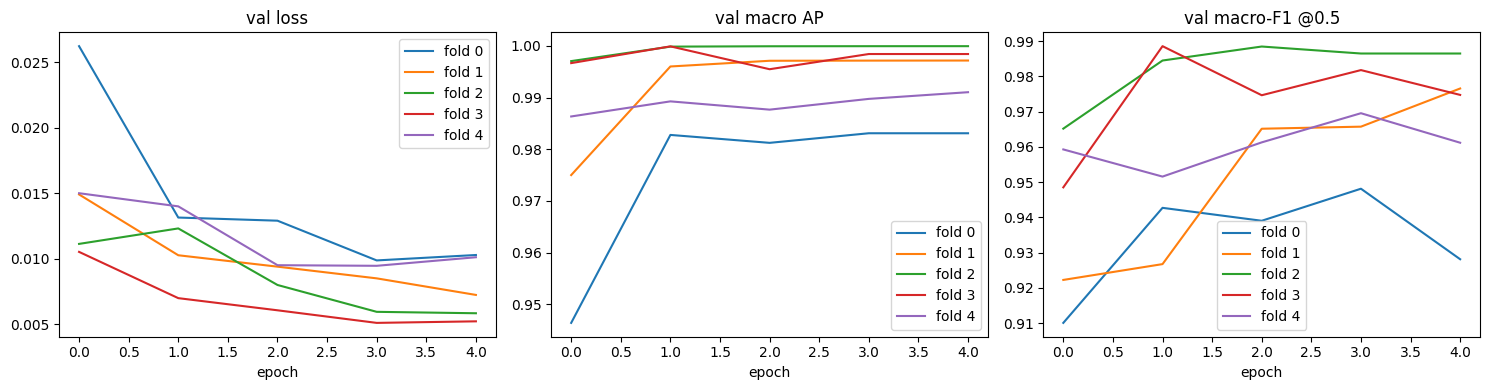

In [24]:
done = np.isin(folds, list(FOLDS_TO_RUN))
print(evaluate_oof(Y[done].astype(int), oof[done], folds[done]))

eps = 1e-7
oof_clipped = np.clip(oof[done], eps, 1 - eps)
print("CV log loss:", -np.mean(Y[done] * np.log(oof_clipped) + (1 - Y[done]) * np.log(1 - oof_clipped)))

hist = pd.DataFrame(history)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for fold, h in hist.groupby("fold"):
    ax[0].plot(h["epoch"], h["val_loss"], label=f"fold {fold}")
    ax[1].plot(h["epoch"], h["val_ap"], label=f"fold {fold}")
    ax[2].plot(h["epoch"], h["val_f1"], label=f"fold {fold}")
for a, title in zip(ax, ["val loss", "val macro AP", "val macro-F1 @0.5"]):
    a.set_title(title)
    a.set_xlabel("epoch")
    a.legend()
plt.tight_layout()
plt.show()

out = pd.DataFrame(oof, columns=LABELS)
out.insert(0, "image_id", ids)
out.loc[~done, LABELS] = np.nan                                 
out.to_csv("oof_effb3_baseline.csv", index=False)

In [26]:
test_ids = pd.read_csv(DATA_DIR / "test.csv")["image_id"].values
test_loader = DataLoader(JpgDataset(test_ids, DATA_DIR / "test", np.zeros((len(test_ids), len(LABELS)), np.float32), test_tf),
                         batch_size=BATCH_SIZE * 2, shuffle=False, num_workers=NUM_WORKERS, pin_memory=use_amp)

model = timm.create_model(MODEL_NAME, pretrained=False, num_classes=len(LABELS)).to(device)
test_probs = []
for fold in FOLDS_TO_RUN:
    model.load_state_dict(torch.load(f"effb3_baseline_fold{fold}.pt", map_location=device))
    model.eval()
    with torch.no_grad():
        logits = torch.cat([model(prep(x)) for x, _ in test_loader]).float()
    test_probs.append(torch.sigmoid(logits).cpu().numpy())
    print(f"fold {fold} predicted")
test_mean = np.mean(test_probs, axis=0)

th = best_thresholds(Y[done].astype(int), oof[done])
print("tuned thresholds:", dict(zip(LABELS, th.round(2).tolist())))

for name, t in [("th05", 0.5), ("tuned", th)]:
    sub = pd.DataFrame((test_mean >= t).astype(int), columns=LABELS)
    sub.insert(0, "image_id", test_ids)
    sub.to_csv(f"submission_effb3_baseline_{name}.csv", index=False)
    print(f"{name:5s} test positive rate:", sub[LABELS].mean().round(4).to_dict())
print("train positive rate:", df[LABELS].mean().round(4).to_dict())


probs = pd.DataFrame(test_mean, columns=LABELS)
probs.insert(0, "image_id", test_ids)
probs.to_csv("test_effb3_baseline.csv", index=False)

fold 0 predicted
fold 1 predicted
fold 2 predicted
fold 3 predicted
fold 4 predicted
tuned thresholds: {'Cat': 0.42, 'Dog': 0.43, 'Moris': 0.58, 'Motya': 0.18, 'Biatrix': 0.23}
th05  test positive rate: {'Cat': 0.4159, 'Dog': 0.409, 'Moris': 0.009, 'Motya': 0.0068, 'Biatrix': 0.0089}
tuned test positive rate: {'Cat': 0.4166, 'Dog': 0.41, 'Moris': 0.0087, 'Motya': 0.0075, 'Biatrix': 0.0093}
train positive rate: {'Cat': 0.4141, 'Dog': 0.4099, 'Moris': 0.0046, 'Motya': 0.0034, 'Biatrix': 0.0033}
